# MSMPR–DPBE de KNO₃: sensibilidad y frente de Pareto

Modelo isotérmico de una población, con **crecimiento independiente del tamaño y
nucleación primaria**. Volumen constante, alimentación sin semillas, extracción
representativa de pulpa y tiempo físico en segundos. Se desprecia explícitamente
la evaporación: el agua evaporada se repone inmediatamente, con efecto neto nulo
sobre volumen y concentración. No hay balance energético, agitación, nucleación
secundaria, ripening, aglomeración ni rotura. No se modela disolución.

Las impurezas se calculan **después** de resolver el DPBE, sin retroalimentación.
Los valores de KNO₃ conservados del notebook de referencia son **supuestos
ilustrativos sin calibración**; las cifras resultantes no son predicciones de planta.

Ejecutar todas las celdas en orden con Python ≥3.10, NumPy, Matplotlib, pandas e
IPython (p. ej., `python -m pip install numpy matplotlib pandas ipykernel`).
No se necesita CasADi, do-mpc, SciPy ni conexión a internet. Todo el modelo está
en este notebook. La última sección exporta tablas y verificaciones a una
**carpeta de ejecución nueva** junto a él, sin sobrescribir resultados anteriores.

## Procedencia y cambios respecto a los archivos existentes

Las celdas de referencia se numeran desde **0**; además se indican funciones para
localizarlas si cambia su orden. Las referencias son documentación, no código ejecutado.

| Elemento | Archivo y ubicación | Uso o cambio |
|---|---|---|
| Alimentación, equipo y supuestos KNO₃ | [Notebook de referencia](../msmpr_dpbe/Evaporative_MSMPR_DPBE.ipynb), celda 2, `BASE` | V=660 m³; concentración 220 kg/m³; τ de referencia=660/(280.83/3600) s. Se adopta **5 % de dilución** como nuevo caso base, para admitir perturbaciones a ambos lados. |
| Cierre MSMPR | [Modelo original](../examples/msmpr/template_model.py), función `model`, `PBE_diff`, `dmc_dt`, `dot_c` | Se conserva mezcla perfecta, extracción n/τ y transferencia soluto→cristal. Se fija T y se expresa C en kg/m³ de volumen nominal. |
| Esquema espacial | [Solver original](../PBE_sol/PBE.py), `PBE.rhs`, rama DPBE, `scheme == 'first'` | Se reutiliza el flujo upwind de primer orden. Se corrige el flujo de frontera a **B**, en lugar de B/G; no se multiplica el transporte por τ. |
| Auditoría de unidades y discretización | [Base revisada](../docs/kno3_model_basis.md), `Existing code audit` | Sustenta las correcciones anteriores. Se utiliza malla uniforme y segundos en todos los balances. |
| Cinética y solubilidad KNO₃ simplificadas | Notebook de referencia, celda 9, `solubility`, `growth_rate`, `nucleation_rate` | Se conservan las leyes potenciales y exponencial ilustrativas, suprimiendo multiplicadores y fenómenos opcionales. |
| Correlaciones del sistema original | [cryst.py](../PBE_sol/cryst.py), `solubility`, `G`, `nucl`; [auditoría](../msmpr_dpbe/auditoria_parametros.md), §1 | Son de L-alanina o valores dummy; **no se transfieren sus coeficientes a KNO₃**. |
| Momentos y percentiles | [population_balance.py](../msmpr_dpbe/population_balance.py), `make_grid`, `volume_percentiles`; referencia, celdas 11–14 | Se reutilizan promedios exactos de Lᵏ en cada celda e inversión de la CDF volumétrica. |
| Impureza, Kd y objetivo de producto | Referencia, celda 2 y `steady_crystal_perchlorate_ppm`; [informe](../investigacion_parametros_DPBE/informe_parametros.md), párrafos `Información interna de perclorato` y `Un Kd definido` | Kd=0.01 es provisional. Se usa ClO₄ solamente; no se suma KClO₄ a la misma especie. La interpretación mg/L del ensayo es un supuesto editable. 40 ppm es objetivo del producto refinado, no una especificación validada del cristal sin lavar. |

Se aproxima el volumen de líquido por el volumen nominal de pulpa, como en el
modelo original: no hay corrección por desplazamiento de sólidos. Se informa
φₛ y se exige φₛ<0.05 para limitar esta aproximación. La alimentación contiene
solo KNO₃ equivalente y una impureza traza; no se reconstruye especiación ni se
añaden al balance los ensayos iónicos incompletos de la referencia.


## 1. Configuración centralizada

`feed_dilution_fraction=d` es la fracción volumétrica del caudal total sustituida
por agua: Q_stock=(1−d)Q, Q_agua=dQ y **todos los solutos modelados** satisfacen
C_f,j=(1−d)C_stock,j. Se supone aditividad de volúmenes. El caudal total permanece
constante al variar d; al variar τ, se recalcula **Q=V/τ**.

La densidad de líquido se usa exclusivamente para convertir C_P [kg/m³] a
w_P,l [kg/kg de líquido]; es una aproximación constante, sin efecto en el DPBE.
`reference_temperature_C` fija el origen de la correlación, no es un parámetro
termodinámico independiente que deba perturbarse.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from itertools import product
from copy import deepcopy
import hashlib
import json
import math
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 15)

BASE = {
    'volume_m3': 660.0,
    'feed_dilution_fraction': 0.05,
    'crystallizer_temperature_C': 40.0,
    'residence_time': 660.0 / (280.83 / 3600.0),  # s; Q es siempre derivado
    'feed_stock_kg_m3': {'KNO3': 220.0, 'ClO4': 3.799262673e-3},
    'reference_temperature_C': 40.0,
    'Cstar_ref_kg_m3': 180.0,
    'solubility_slope_K_inv': 0.010,
    'kG_m_s': 2.0e-7,
    'g': 1.0,
    'kB_m3_s_inv': 1.0e10,
    'b': 2.0,
    'rho_crystal_kg_m3': 2100.0,
    'kv': math.pi / 6.0,
    'Kd': 0.01,
    'rho_liquid_kg_m3': 1040.0,
}
INITIAL = {'C_kg_m3': 180.0, 'seed_number_m3': 0.0}
NUM = {
    'bins': 480, 'Lmax_m': 1.2e-3, 'cfl': 0.65,
    'max_step_s': 40.0, 'sample_every_tau': 0.1,
    'duration_tau': 30.0, 'stationary_tolerance': 1e-8,
    'mass_tolerance': 2e-10, 'tail_tolerance': 1e-5,
    'solid_volume_fraction_limit': 0.05,
    'mesh_tolerance': 0.04, 'time_tolerance': 0.005,
    'transient_stationary_tolerance': 5e-4,
}
ANALYSIS = {
    'parameter_relative_changes': [-0.10, -0.05, 0.05, 0.10],
    'negligible_elasticity': 0.01,
    'operating_bounds': {
        'feed_dilution_fraction': (0.0, 0.15),
        'crystallizer_temperature_C': (35.0, 45.0),
        'residence_time': (0.6 * BASE['residence_time'],
                           1.4 * BASE['residence_time']),
    },
    'pareto_points_per_axis': (7, 9, 7),
    'quality_limit_ppm': 40.0,
}
heatmap_inputs = [
    ('feed_dilution_fraction', 'Dilution'),
    ('crystallizer_temperature_C', 'Temperature'),
    ('residence_time', 'Residence time'),
]
heatmap_outputs = [
    ('crystal_flow_kg_h', 'Crystal flow'),
    ('D50_um', 'D50'),
    ('S', 'Supersaturation'),
    ('impurity_ppm', 'Impurity content'),
]
PARAMETERS = {
    # nombre: (unidad, grupo, límite inferior exclusivo, superior inclusivo)
    'kG_m_s': ('m/s', 'DPBE: cinético', 0, np.inf),
    'g': ('1', 'DPBE: cinético', 0, 5),
    'kB_m3_s_inv': ('m⁻³ s⁻¹', 'DPBE: cinético', 0, np.inf),
    'b': ('1', 'DPBE: cinético', 0, 6),
    'Cstar_ref_kg_m3': ('kg/m³', 'DPBE: termodinámico', 0, np.inf),
    'solubility_slope_K_inv': ('K⁻¹', 'DPBE: termodinámico', 0, 0.2),
    'rho_crystal_kg_m3': ('kg/m³', 'DPBE: cristalográfico', 1000, 4000),
    'kv': ('1', 'DPBE: cristalográfico', 0, 1),
    'Kd': ('1', 'solo impurezas', 0, 1),
    'rho_liquid_kg_m3': ('kg/m³', 'solo impurezas', 900, 2000),
}
parameter_table = pd.DataFrame([
    {'parámetro': key, 'base': BASE[key], 'unidad': info[0],
     'grupo': info[1], 'procedencia': 'Referencia celda 2; supuesto no calibrado'}
    for key, info in PARAMETERS.items()
])
display(parameter_table)
display(pd.DataFrame([{'variable': k, 'valor base': BASE[k],
                      'unidad': u}
                     for k, u in [('volume_m3', 'm³'),
                                  ('feed_dilution_fraction', '1'),
                                  ('crystallizer_temperature_C', '°C'),
                                  ('residence_time', 's')]]))
print('C_stock,KNO3 = 220 kg/m³; C_stock,ClO4 = 3.799262673 mg/L (supuesto).')
print('C inicial =', INITIAL['C_kg_m3'], 'kg/m³; población inicial y de alimentación = 0.')
print('El diámetro equivalente se adopta solo en el caso kv=π/6; al variar kv se fija L.')


C_stock,KNO3 = 220 kg/m³; C_stock,ClO4 = 3.799262673 mg/L (supuesto).
C inicial = 180.0 kg/m³; población inicial y de alimentación = 0.
El diámetro equivalente se adopta solo en el caso kv=π/6; al variar kv se fija L.


,parámetro,base,unidad,grupo,procedencia
0,kG_m_s,2.000000e-07,m/s,DPBE: cinético,Referencia celda 2; supuesto no calibrado
1,g,1.000000e+00,1,DPBE: cinético,Referencia celda 2; supuesto no calibrado
2,kB_m3_s_inv,1.000000e+10,m⁻³ s⁻¹,DPBE: cinético,Referencia celda 2; supuesto no calibrado
3,b,2.000000e+00,1,DPBE: cinético,Referencia celda 2; supuesto no calibrado
4,Cstar_ref_kg_m3,1.800000e+02,kg/m³,DPBE: termodinámico,Referencia celda 2; supuesto no calibrado
5,solubility_slope_K_inv,1.000000e-02,K⁻¹,DPBE: termodinámico,Referencia celda 2; supuesto no calibrado
6,rho_crystal_kg_m3,2.100000e+03,kg/m³,DPBE: cristalográfico,Referencia celda 2; supuesto no calibrado
7,kv,5.235988e-01,1,DPBE: cristalográfico,Referencia celda 2; supuesto no calibrado
8,Kd,1.000000e-02,1,solo impurezas,Referencia celda 2; supuesto no calibrado
9,rho_liquid_kg_m3,1.040000e+03,kg/m³,solo impurezas,Referencia celda 2; supuesto no calibrado


,variable,valor base,unidad
0,volume_m3,660.000000,m³
1,feed_dilution_fraction,0.050000,1
2,crystallizer_temperature_C,40.000000,°C
3,residence_time,8460.634548,s


## 2. Ecuaciones, unidades y discretización conservativa

Se conserva la formulación MSMPR del original citado arriba:

\[
\partial_t n+\partial_L(Gn)=-n/\tau,\quad (Gn)_{L=0}=B,
\qquad \dot C=(C_f-C)/\tau-R.
\]

S=C/C*(T) es la **razón de saturación**, adimensional; σ=max(S−1,0) es el exceso
relativo usado en G=k_G σᵍ [m/s] y B=k_B σᵇ [número/(m³·s)].
C*=C*_ref exp[a(T−T_ref)] está en kg/m³, igual que C y C_f. Las diferencias
de temperatura en K y °C coinciden. No se usa sobresaturación de actividades.

Para las celdas de tamaño [aᵢ,bᵢ], Nᵢ=nᵢ ΔL [número/m³],
qₖ,ᵢ=(bᵢ^(k+1)−aᵢ^(k+1))/[(k+1)ΔL] y μₖ=Σqₖ,ᵢNᵢ.
Así μ₀, μ₁, μ₂, μ₃ tienen unidades m⁻³, m⁻², m⁻¹ y 1.

\[
\dot N_i=J_i-J_{i+1}-N_i/\tau,\quad J_0=B,\quad
J_{i+1}=G N_i/\Delta L,\quad m_i=\rho_s k_v q_{3,i},
\]
\[
M=\sum_i m_iN_i=\rho_s k_v\mu_3\ [\mathrm{kg/m^3}],\quad
R=\mathbf m\cdot(\mathbf J_{in}-\mathbf J_{out})
  +\rho_s k_v L_{max}^3J_{N}.
\]

El mismo R discretizado se resta del líquido una sola vez. **No** se añade además
3ρₛkᵥGμ₂ ni otro sumidero por nucleación. La masa de la primera celda asociada a
nacimientos es una regularización de tamaño finito, que desaparece al refinar.
La salida numérica por Lmax se registra por separado y se exige despreciable:

\[
\dot{(C+M)}=(C_f-C-M)/\tau-r_{tail},\quad
r_{tail}=\rho_s k_vL_{max}^3 J_N.
\]

El flujo producido de **KNO₃ anfitrión** es 3600QM [kg/h].
D50 es el percentil **volumétrico**, también másico para densidad uniforme:
∫₀ᴰ⁵⁰L³n dL / μ₃=0.5. Se invierte exactamente dentro de la celda, sin usar
μ₄/μ₃ como mediana. No hay D50 ni ppm de producto si no existen cristales.


In [2]:
def bisect_root(fun, low, high, rtol=1e-13):
    """Bisección escalar determinista; requiere cambio de signo."""
    fl, fh = fun(low), fun(high)
    if fl == 0:
        return low
    if fh == 0:
        return high
    if fl * fh > 0:
        raise ValueError('La raíz no está encerrada.')
    for _ in range(100):
        mid = (low + high) / 2
        fm = fun(mid)
        if fm == 0 or high - low <= rtol * max(abs(mid), 1e-15):
            return mid
        if fl * fm <= 0:
            high = mid
        else:
            low, fl = mid, fm
    raise RuntimeError('Bisección sin convergencia.')


def validate_parameters(p):
    assert p['volume_m3'] > 0 and p['residence_time'] > 0
    assert 0 <= p['feed_dilution_fraction'] < 1
    assert p['crystallizer_temperature_C'] > -273.15
    assert all(value >= 0 for value in p['feed_stock_kg_m3'].values())
    for key, (_, _, lo, hi) in PARAMETERS.items():
        assert lo < p[key] <= hi, (key, p[key])


def feed(p):
    return {key: (1 - p['feed_dilution_fraction']) * value
            for key, value in p['feed_stock_kg_m3'].items()}


def flow(p):
    return p['volume_m3'] / p['residence_time']


def cstar(p):
    return p['Cstar_ref_kg_m3'] * np.exp(p['solubility_slope_K_inv'] *
        (p['crystallizer_temperature_C'] - p['reference_temperature_C']))


def kinetics(C, p):
    S = C / cstar(p)
    sigma = max(S - 1.0, 0.0)
    return S, p['kG_m_s'] * sigma**p['g'], p['kB_m3_s_inv'] * sigma**p['b']


def make_grid(p, num=NUM):
    edges = np.linspace(0, num['Lmax_m'], num['bins'] + 1)
    dl = edges[1] - edges[0]
    q = np.array([(edges[1:]**(k+1) - edges[:-1]**(k+1)) /
                  ((k+1)*dl) for k in range(4)])
    return {'edges': edges, 'dl': dl, 'q': q,
            'centers': (edges[:-1] + edges[1:])/2,
            'mass': p['rho_crystal_kg_m3'] * p['kv'] * q[3],
            'edge_mass': p['rho_crystal_kg_m3'] * p['kv'] * edges[-1]**3}


def population_terms(C, N, p, grid):
    """Retorna transporte, extracción, formación y fuga de masa por Lmax."""
    _, G, B = kinetics(C, p)
    J = np.r_[B, G * N / grid['dl']]
    transport = J[:-1] - J[1:]
    tail = grid['edge_mass'] * J[-1]
    formation = np.dot(grid['mass'], transport) + tail
    return transport - N/p['residence_time'], formation, tail, J[-1]


def d50(N, grid):
    weights = grid['q'][3] * N
    if weights.sum() <= 0:
        return np.nan
    cumulative = np.cumsum(weights)
    target = 0.5 * cumulative[-1]
    i = min(np.searchsorted(cumulative, target), len(N)-1)
    before = cumulative[i-1] if i else 0.0
    fraction = (target - before) / weights[i]
    a, b = grid['edges'][i:i+2]
    return 1e6 * (a**4 + fraction * (b**4-a**4))**0.25


def state_metrics(C, N, p, grid):
    moments = grid['q'] @ N
    M = float(grid['mass'] @ N)
    S, G, B = kinetics(C, p)
    return {'C_kg_m3': C, 'M_kg_m3': M, 'S': S, 'sigma': S-1,
            'G_m_s': G, 'B_m3_s_inv': B,
            'crystal_flow_kg_h': 3600*flow(p)*M,
            'D50_um': d50(N, grid),
            'phi_s': p['kv']*moments[3],
            **{f'mu{k}': value for k, value in enumerate(moments)}}


### Solución estacionaria del DPBE y postprocesamiento de impurezas

Para G y B constantes en una solución estacionaria, la ecuación de cada celda
es triangular: N₀=B/(G/ΔL+1/τ), Nᵢ=Nᵢ₋₁·(G/ΔL)/(G/ΔL+1/τ).
Se obtiene C mediante bisección de (C_f−C)/τ−R(C)=0 entre C* y C_f.
Esto resuelve el **DPBE discretizado**, no sustituye la población por momentos.
Si C_f≤C*, el estado estacionario sin semillas tiene N=0 y C=C_f.

Después se impone w_P,s=Kd·w_P,l, con w_P,l=C_P/ρ_l y
ppm=10⁶w_P,s **[mg ClO₄/kg de cristal seco total antes del lavado]**.
Para no crear impureza artificialmente se cierra, por separado, el balance
estacionario de la traza:

\[
Q C_{P,f}=Q C_P+
\frac{\dot m_{KNO3}+\dot m_{tail}}{1-w_{P,s}}w_{P,s}.
\]

Se resuelve una segunda bisección, exclusivamente de postprocesamiento.
El denominador 1−w_P,s convierte masa de anfitrión a masa total sin cambiar el
balance de KNO₃. El transporte por Lmax se incluye como corrección numérica
despreciable. No se calculan cinéticas transitorias de incorporación, lavado,
adsorción, oclusión ni solubilidad de sales de impureza. La densidad, Kd y el
ensayo de ClO₄ no afectan C, G, B, CSD o producción de KNO₃.


In [3]:
DPBE_CACHE = {}


def stationary_dpbe(p, num=NUM):
    validate_parameters(p)
    # Kd, rho_liquid y el ensayo de la traza están ausentes de la clave del DPBE.
    key = (num['bins'], num['Lmax_m'], *(p[k] for k in
        ('volume_m3', 'feed_dilution_fraction', 'crystallizer_temperature_C',
         'residence_time', 'reference_temperature_C', 'Cstar_ref_kg_m3',
         'solubility_slope_K_inv', 'kG_m_s', 'g', 'kB_m3_s_inv', 'b',
         'rho_crystal_kg_m3', 'kv')), p['feed_stock_kg_m3']['KNO3'])
    if key in DPBE_CACHE:
        return DPBE_CACHE[key]
    grid = make_grid(p, num)
    tau, Cf = p['residence_time'], feed(p)['KNO3']

    def distribution(C):
        _, G, B = kinetics(C, p)
        a = G / grid['dl']
        return (B / (a+1/tau)) * (a/(a+1/tau))**np.arange(num['bins'])

    def residual(C):
        N = distribution(C)
        return (Cf-C)/tau - population_terms(C, N, p, grid)[1]

    C = Cf if Cf <= cstar(p) else bisect_root(residual, cstar(p), Cf)
    N = distribution(C)
    dN, R, tail, number_tail = population_terms(C, N, p, grid)
    met = state_metrics(C, N, p, grid)
    scale = max(Cf, 1e-15)
    met.update({
        'stationary_residual': max(abs(residual(C))*tau/scale,
            np.max(np.abs(dN))*tau/max(np.max(N), 1.0)),
        'mass_residual': abs(Cf-C-met['M_kg_m3']-tau*tail)/scale,
        'tail_mass_fraction': tail/max(R, 1e-30),
        'tail_number_fraction': number_tail/max(met['B_m3_s_inv'], 1e-30),
        'formation_kg_m3_s': R, 'tail_kg_m3_s': tail,
        'Q_m3_h': flow(p)*3600,
    })
    valid = (met['stationary_residual'] < num['stationary_tolerance']
        and met['mass_residual'] < num['mass_tolerance']
        and met['tail_mass_fraction'] < num['tail_tolerance']
        and met['phi_s'] < num['solid_volume_fraction_limit']
        and C >= 0 and np.min(N) >= 0)
    result = {'C': C, 'N': N, 'grid': grid, 'metrics': met, 'valid': bool(valid)}
    DPBE_CACHE[key] = result
    return result


def impurity_postprocess(p, dpbe):
    """Cierre de traza independiente; no modifica dpbe ni sus parámetros."""
    m = dpbe['metrics']
    Q, rho, Kd = flow(p), p['rho_liquid_kg_m3'], p['Kd']
    Cpf = feed(p)['ClO4']
    host_kg_s = m['crystal_flow_kg_h']/3600
    host_tail_kg_s = p['volume_m3']*m['tail_kg_m3_s']
    assert Kd*Cpf/rho < 1, 'Fracción sólida de impureza no física.'
    if host_kg_s <= 1e-12:
        return {'impurity_ppm': np.nan, 'C_P_liquid_kg_m3': Cpf,
                'impurity_balance_relative': 0.0, 'impurity_solid_kg_h': 0.0}

    def trace_residual(Cp):
        ws = Kd*Cp/rho
        return Q*(Cpf-Cp) - (host_kg_s+host_tail_kg_s)*ws/(1-ws)

    Cp = bisect_root(trace_residual, 0.0, Cpf)
    ws = Kd*Cp/rho
    return {'impurity_ppm': 1e6*ws, 'C_P_liquid_kg_m3': Cp,
            'impurity_balance_relative': abs(trace_residual(Cp))/max(Q*Cpf, 1e-30),
            'impurity_solid_kg_h': 3600*host_kg_s*ws/(1-ws)}


def evaluate(p, num=NUM):
    dpbe = stationary_dpbe(p, num)
    # Un balance conservado no garantiza una CSD resuelta cerca de saturación.
    # Cada punto se contrasta con el mismo DPBE en malla doble; la caché evita
    # repetirlo para BASE o para parámetros que afectan solo al postprocesamiento.
    refined = stationary_dpbe(p, {**num, 'bins': 2*num['bins']})
    compared = ('crystal_flow_kg_h', 'D50_um', 'S')
    errors = [abs(refined['metrics'][key]/dpbe['metrics'][key]-1)
              for key in compared if np.isfinite(dpbe['metrics'][key])
              and abs(dpbe['metrics'][key]) > 1e-30]
    mesh_error = max(errors, default=0.0)
    resolved = mesh_error < num['mesh_tolerance']
    return {**dpbe['metrics'], **impurity_postprocess(p, dpbe),
            'mesh_relative_max': mesh_error, 'mesh_resolved': resolved,
            'valid': bool(dpbe['valid'] and refined['valid'] and resolved),
            'has_product': bool(dpbe['metrics']['crystal_flow_kg_h'] > 1e-9)}


base_dpbe = stationary_dpbe(BASE)
base = evaluate(BASE)
assert base['valid'] and base['has_product']
display(pd.DataFrame([base]).T.rename(columns={0: 'Caso base estacionario'}))


,Caso base estacionario
C_kg_m3,184.359236
M_kg_m3,24.640764
S,1.024218
sigma,0.024218
G_m_s,0.0
B_m3_s_inv,5865105.274613
crystal_flow_kg_h,6919.865659
D50_um,155.013496
phi_s,0.011734
mu0,49622512311.62281


### Integración temporal independiente y conservación acumulada

Se aplica SSP-RK2 explícito a las mismas ecuaciones. El paso cumple el CFL
del transporte y extracción y un límite de inventario disuelto. Si una etapa
produce C o N negativos, se reduce el paso y se repite; **no se recortan estados**.
Se integran simultáneamente los acumuladores de salida disuelta, sólida y por
Lmax con el mismo RK2. El error de masa mide inventario más salidas menos
inventario inicial y alimentación acumulada.


In [4]:
def dynamic_rhs(y, p, grid):
    C, N = y[0], y[1:-3]
    dN, R, tail, _ = population_terms(C, N, p, grid)
    M = grid['mass'] @ N
    return np.r_[(feed(p)['KNO3']-C)/p['residence_time']-R, dN,
                 C/p['residence_time'], M/p['residence_time'], tail]


def integrate(p, num=NUM):
    if INITIAL['seed_number_m3'] != 0:
        raise ValueError('Este caso configura arranque sin semillas.')
    grid = make_grid(p, num)
    y = np.r_[INITIAL['C_kg_m3'], np.zeros(num['bins']), np.zeros(3)]
    t, end = 0.0, num['duration_tau']*p['residence_time']
    sample = num['sample_every_tau']*p['residence_time']
    next_sample, records, populations = 0.0, [], []
    initial_total = y[0]
    max_error, min_C, min_N, rejected, steps = 0.0, y[0], 0.0, 0, 0
    while True:
        if t >= next_sample - 1e-8 or t >= end - 1e-8:
            metrics = state_metrics(y[0], y[1:-3], p, grid)
            error = (y[0] + metrics['M_kg_m3'] + y[-3:].sum()
                     - initial_total - feed(p)['KNO3']*t/p['residence_time'])
            records.append({'time_s': t, 'time_tau': t/p['residence_time'],
                            'mass_error_kg_m3': error, **metrics})
            populations.append(y[1:-3].copy())
            next_sample += sample
        if t >= end - 1e-8:
            break
        _, G, _ = kinetics(y[0], p)
        rhs0 = dynamic_rhs(y, p, grid)
        dt = min(num['max_step_s'], end-t, next_sample-t,
                 num['cfl']/(G/grid['dl']+1/p['residence_time']))
        if rhs0[0] < 0:
            dt = min(dt, 0.8*y[0]/(-rhs0[0]))
        for attempt in range(50):
            stage = y + dt*rhs0
            if np.min(stage[:-3]) >= 0:
                trial = 0.5*y + 0.5*(stage+dt*dynamic_rhs(stage, p, grid))
                _, G1, _ = kinetics(stage[0], p)
                if (np.min(trial[:-3]) >= 0 and
                    dt*(G1/grid['dl']+1/p['residence_time']) <= num['cfl']):
                    break
            dt *= 0.5
            rejected += 1
        else:
            raise RuntimeError('No se encontró un paso positivo.')
        y, t = trial, t+dt
        steps += 1
        total = y[0] + grid['mass'] @ y[1:-3] + y[-3:].sum()
        error = total-initial_total-feed(p)['KNO3']*t/p['residence_time']
        max_error = max(max_error, abs(error)/max(initial_total+
            feed(p)['KNO3']*t/p['residence_time'], 1))
        min_C, min_N = min(min_C, y[0]), min(min_N, np.min(y[1:-3]))
        if steps > 2_000_000 or dt < 1e-10:
            raise RuntimeError('Integración estancada.')
    final_rhs = dynamic_rhs(y, p, grid)
    rate_residual = max(abs(final_rhs[0])*p['residence_time']/feed(p)['KNO3'],
        np.max(abs(final_rhs[1:-3]))*p['residence_time']/max(np.max(y[1:-3]), 1))
    return {'trajectory': pd.DataFrame(records), 'N_history': np.array(populations),
            'N': y[1:-3], 'grid': grid, 'steps': steps, 'rejected': rejected,
            'max_mass_relative': max_error, 'min_C': min_C, 'min_N': min_N,
            'final_rate_residual': rate_residual}


transient = integrate(BASE)
trajectory = transient['trajectory']
print(f"Integración: {transient['steps']} pasos, {transient['rejected']} reducciones.")
print('Residuo dinámico final escalado:', transient['final_rate_residual'])


Integración: 6600 pasos, 0 reducciones.
Residuo dinámico final escalado: 2.147140421947287e-10


## 3. Momentos, CSD y principales resultados

Las líneas discontinuas corresponden a la solución estacionaria algebraica.
Las curvas transitorias se muestran hasta 30τ; su cercanía visual no sustituye
las comprobaciones numéricas de la sección 7.


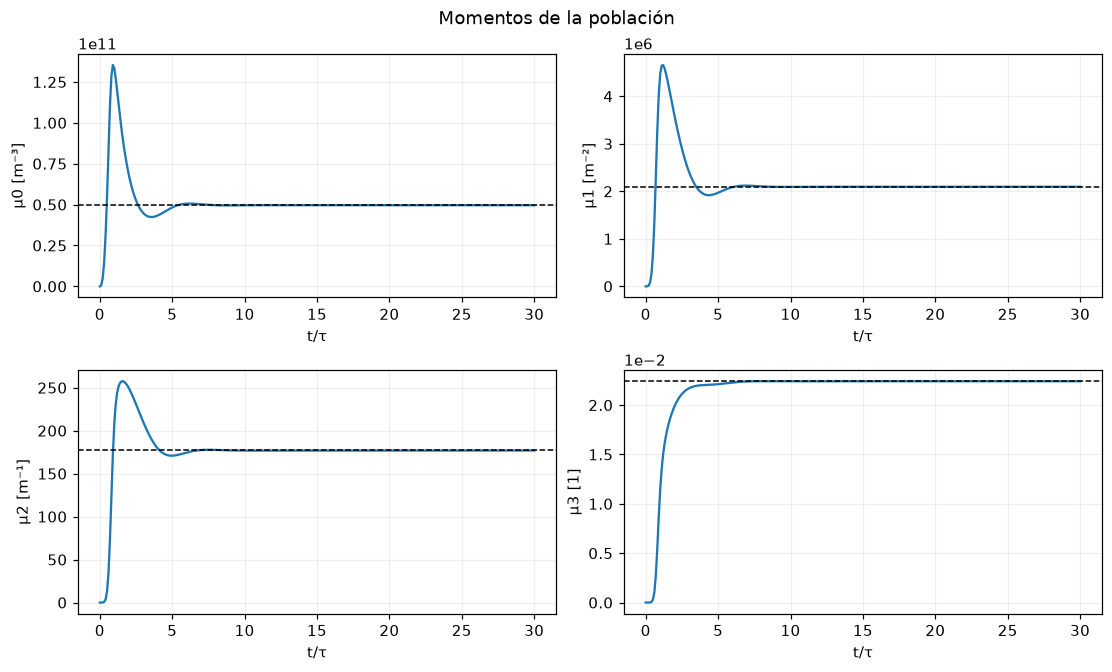

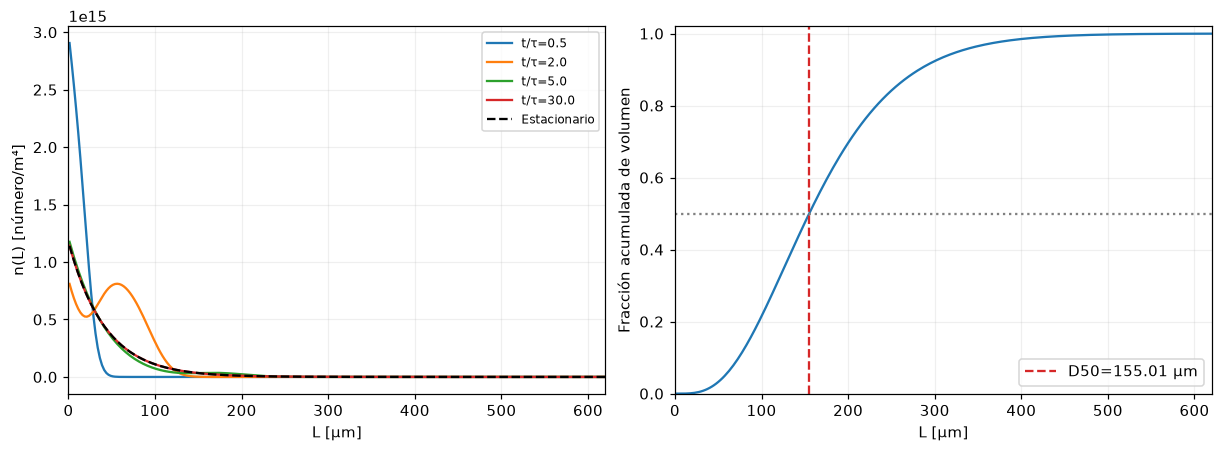

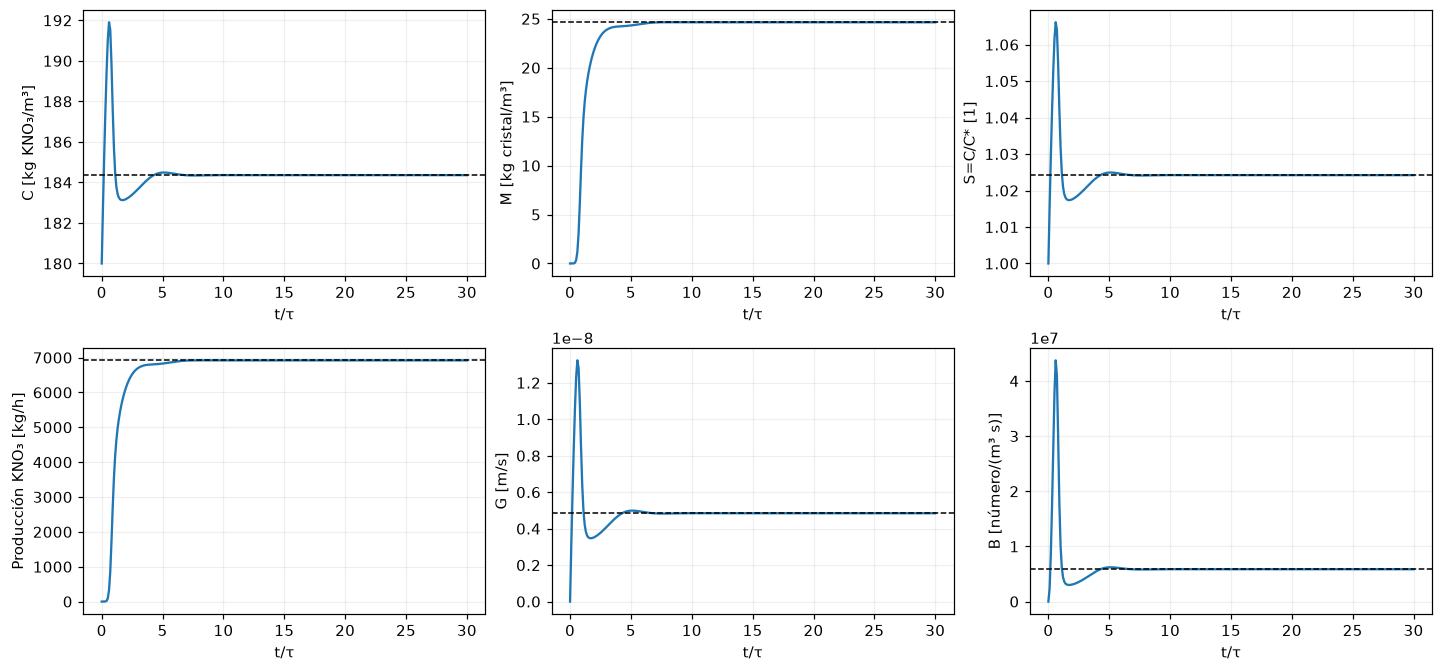

,Producción KNO3 [kg/h],D50 volumen [µm],S [1],σ [1],ClO4 cristal [mg/kg seco],ClO4 licor [mg/L],Conversión KNO3 alimentado [%],φs [1]
0,6919.865659,155.013496,1.024218,0.024218,0.034697,3.608445,11.789839,0.011734


In [5]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6), constrained_layout=True)
for k, ax, unit in zip(range(4), axs.flat, ['m⁻³', 'm⁻²', 'm⁻¹', '1']):
    ax.plot(trajectory['time_tau'], trajectory[f'mu{k}'])
    ax.axhline(base[f'mu{k}'], ls='--', color='black', lw=1)
    ax.set(xlabel='t/τ', ylabel=f'μ{k} [{unit}]')
    ax.ticklabel_format(axis='y', style='sci', scilimits=(-2, 3))
fig.suptitle('Momentos de la población')
plt.show()

grid = base_dpbe['grid']
fig, axs = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for target_tau in (0.5, 2.0, 5.0, 30.0):
    j = np.argmin(abs(trajectory['time_tau']-target_tau))
    axs[0].plot(grid['centers']*1e6,
                transient['N_history'][j]/grid['dl'], label=f"t/τ={trajectory.iloc[j]['time_tau']:.1f}")
axs[0].plot(grid['centers']*1e6, base_dpbe['N']/grid['dl'],
            '--', color='black', label='Estacionario')
axs[0].set(xlabel='L [µm]', ylabel='n(L) [número/m⁴]',
           xlim=(0, min(NUM['Lmax_m']*1e6, 4*base['D50_um'])))
axs[0].legend(fontsize=8)
weights = grid['q'][3]*base_dpbe['N']
cdf = np.r_[0, np.cumsum(weights)/weights.sum()]
axs[1].plot(grid['edges']*1e6, cdf)
axs[1].axvline(base['D50_um'], ls='--', color='tab:red',
               label=f"D50={base['D50_um']:.2f} µm")
axs[1].axhline(0.5, ls=':', color='gray')
axs[1].set(xlabel='L [µm]', ylabel='Fracción acumulada de volumen',
           xlim=axs[0].get_xlim(), ylim=(0, 1.02))
axs[1].legend()
plt.show()

fig, axs = plt.subplots(2, 3, figsize=(13, 6), constrained_layout=True)
series = [('C_kg_m3', 'C [kg KNO₃/m³]'), ('M_kg_m3', 'M [kg cristal/m³]'),
          ('S', 'S=C/C* [1]'), ('crystal_flow_kg_h', 'Producción KNO₃ [kg/h]'),
          ('G_m_s', 'G [m/s]'), ('B_m3_s_inv', 'B [número/(m³ s)]')]
for ax, (key, label) in zip(axs.flat, series):
    ax.plot(trajectory['time_tau'], trajectory[key])
    ax.axhline(base[key], ls='--', lw=1, color='black')
    ax.set(xlabel='t/τ', ylabel=label)
plt.show()
display(pd.DataFrame([{
    'Producción KNO3 [kg/h]': base['crystal_flow_kg_h'],
    'D50 volumen [µm]': base['D50_um'], 'S [1]': base['S'],
    'σ [1]': base['sigma'], 'ClO4 cristal [mg/kg seco]': base['impurity_ppm'],
    'ClO4 licor [mg/L]': 1e3*base['C_P_liquid_kg_m3'],
    'Conversión KNO3 alimentado [%]':
        100*base['crystal_flow_kg_h']/(3600*flow(BASE)*feed(BASE)['KNO3']),
    'φs [1]': base['phi_s'],
}]))


## 4. Sensibilidad de variables operacionales

Barridos individuales: se varía una entrada manteniendo todas las demás
iguales al **mismo BASE** anterior. Los mapas muestran
100·(y−y_base)/y_base [%]. En temperatura se indican cambios absolutos en °C,
evitando normalizar con un origen Celsius arbitrario.

Los intervalos 0–15 % de sustitución por agua, 35–45 °C y 0.6–1.4τ_base son
**ventanas de exploración**, no límites certificados del equipo. d∈[0,1) garantiza
concentraciones no negativas; el rango estrecho de T rodea el anclaje a 40 °C
y evita extrapolaciones mayores de la correlación ilustrativa; τ>0 y V fijo
aseguran Q>0. La referencia usa temperaturas 30–50 °C en su barrido. Las
ventanas propuestas son más estrechas y deben sustituirse por datos medidos.
Se descartan de las comparaciones de producto los puntos sin cristales o que
incumplen las verificaciones de truncamiento, masa, resolución espacial o volumen
de sólidos. **Cada evaluación** se contrasta con una malla doble: se exige
cambio <4 % (configurable) en producción, D50 y S. La caché reutiliza soluciones
repetidas; las tablas conservan el error de malla y el indicador de aceptación.


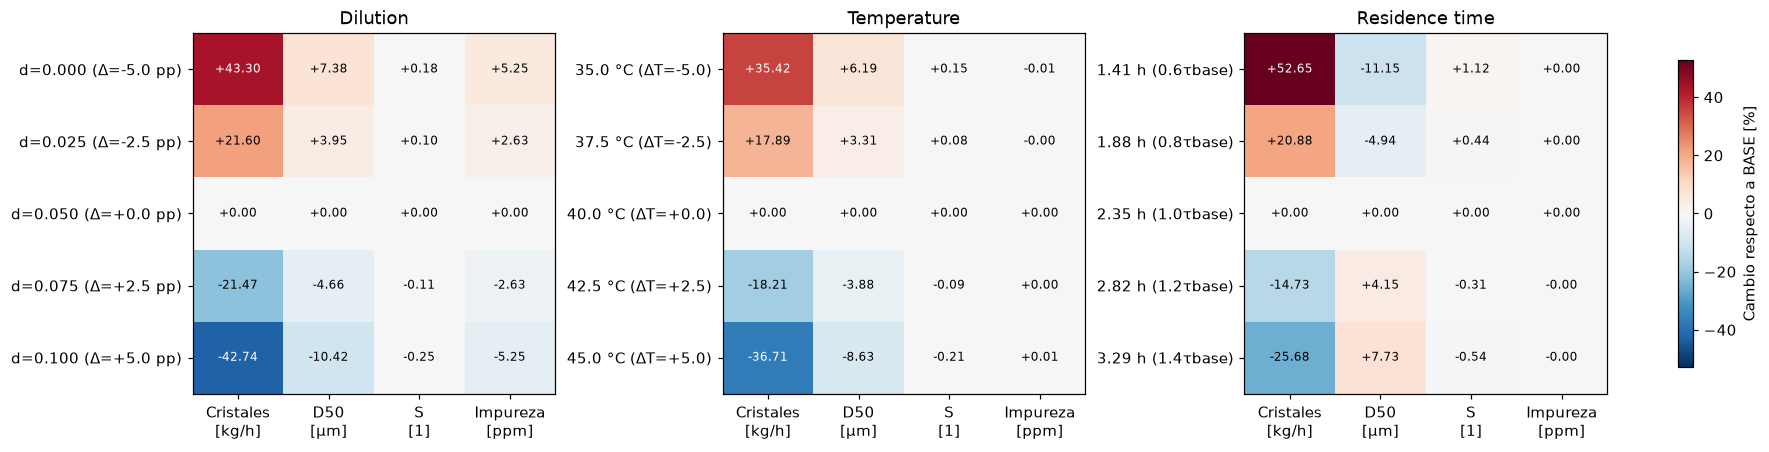

,input,value,Q_m3_h,crystal_flow_kg_h,D50_um,S,impurity_ppm,valid
0,feed_dilution_fraction,0.000000,280.830000,9916.034886,166.460673,1.026057,0.036519,True
1,feed_dilution_fraction,0.025000,280.830000,8414.722171,161.143167,1.025201,0.035608,True
2,feed_dilution_fraction,0.050000,280.830000,6919.865659,155.013496,1.024218,0.034697,True
3,feed_dilution_fraction,0.075000,280.830000,5434.101967,147.790251,1.023055,0.033785,True
4,feed_dilution_fraction,0.100000,280.830000,3962.221793,138.864471,1.021617,0.032874,True
5,crystallizer_temperature_C,35.000000,280.830000,9370.793346,164.601424,1.025759,0.034694,True
6,crystallizer_temperature_C,37.500000,280.830000,8157.501828,160.143106,1.025043,0.034695,True
7,crystallizer_temperature_C,40.000000,280.830000,6919.865659,155.013496,1.024218,0.034697,True
8,crystallizer_temperature_C,42.500000,280.830000,5659.563076,148.992773,1.023246,0.034698,True
9,crystallizer_temperature_C,45.000000,280.830000,4379.883000,141.637186,1.022063,0.034700,True


In [6]:
output_keys = [key for key, _ in heatmap_outputs]
output_labels = ['Cristales\n[kg/h]', 'D50\n[µm]', 'S\n[1]', 'Impureza\n[ppm]']
base_y = np.array([base[key] for key in output_keys])
op_levels = {
    'feed_dilution_fraction': np.array([0, .025, .05, .075, .10]),
    'crystallizer_temperature_C': BASE['crystallizer_temperature_C'] + np.array([-5, -2.5, 0, 2.5, 5]),
    'residence_time': BASE['residence_time'] * np.array([.6, .8, 1, 1.2, 1.4]),
}


def annotated_heatmap(ax, matrix, row_labels, title, color_limit=None):
    matrix = np.asarray(matrix)
    finite = np.abs(matrix[np.isfinite(matrix)])
    limit = max(float(finite.max()) if finite.size else 0, 1e-12)
    if color_limit is not None:
        limit = color_limit
    cmap = plt.get_cmap('RdBu_r').copy()
    cmap.set_bad('#dedede')
    im = ax.imshow(matrix, cmap=cmap, vmin=-limit, vmax=limit, aspect='auto')
    ax.set(xticks=np.arange(4), xticklabels=output_labels,
           yticks=np.arange(len(row_labels)), yticklabels=row_labels, title=title)
    ax.grid(False)
    for (i, j), value in np.ndenumerate(matrix):
        text = f'{value:+.2f}' if np.isfinite(value) else 'N/D'
        ax.text(j, i, text, ha='center', va='center', fontsize=8,
                color='white' if np.isfinite(value) and abs(value) > .65*limit else 'black')
    return im


operating_records = []
for key, label in heatmap_inputs:
    for value in op_levels[key]:
        p = deepcopy(BASE)
        p[key] = float(value)
        result = evaluate(p)
        operating_records.append({'input': key, 'value': value, **result})
operating_sensitivity = pd.DataFrame(operating_records)
matrices, rows = [], []
for key, label in heatmap_inputs:
    subset = operating_sensitivity[operating_sensitivity['input'] == key]
    values = subset[output_keys].to_numpy(copy=True)
    values[~(subset['valid'] & subset['has_product']).to_numpy()] = np.nan
    matrices.append(100*(values/base_y-1))
    if key == 'feed_dilution_fraction':
        rows.append([f'd={v:.3f} (Δ={100*(v-BASE[key]):+.1f} pp)' for v in subset['value']])
    elif key == 'crystallizer_temperature_C':
        rows.append([f'{v:.1f} °C (ΔT={v-BASE[key]:+.1f})' for v in subset['value']])
    else:
        rows.append([f'{v/3600:.2f} h ({v/BASE[key]:.1f}τbase)' for v in subset['value']])
common_limit = max(np.nanmax(abs(mat)) for mat in matrices)
fig, axs = plt.subplots(1, 3, figsize=(16, 4), constrained_layout=True)
for ax, matrix, row_labels, (_, label) in zip(axs, matrices, rows, heatmap_inputs):
    im = annotated_heatmap(ax, matrix, row_labels, label, common_limit)
fig.colorbar(im, ax=axs, label='Cambio respecto a BASE [%]', shrink=.85)
plt.show()
display(operating_sensitivity[['input', 'value', 'Q_m3_h', *output_keys, 'valid']])


## 5. Sensibilidad de parámetros constitutivos

Para cada parámetro activo p, perturbaciones relativas r configurables y todas
las demás variables fijas: E_secante=[y(p(1+r))/y_base−1]/r. El mapa principal
usa la diferencia central E_c=[y(p(1+h))−y(p(1−h))]/(2h·y_base), con
h=max|r| para el que existan ambas perturbaciones. Son sensibilidades
adimensionales (elasticidades); el signo indica la dirección del efecto.
También se muestran las dos amplitudes para comprobar dependencia del paso.
Se registran y excluyen perturbaciones fuera de los límites configurados.

Se estudian todos los coeficientes activos: kG, g, kB, b, C*_ref, a, ρs, kv,
Kd y ρl. Los dos últimos pertenecen solo al postprocesamiento. Condiciones
operacionales, ensayos de alimentación y condiciones iniciales no se confunden
con parámetros constitutivos; los ajustes numéricos se verifican aparte.
La pendiente a es localmente inactiva cuando T=T_ref, sin implicar que lo sea
en otro punto. Los exponentes se perturban manteniendo los prefactores.


Perturbaciones excluidas: 0


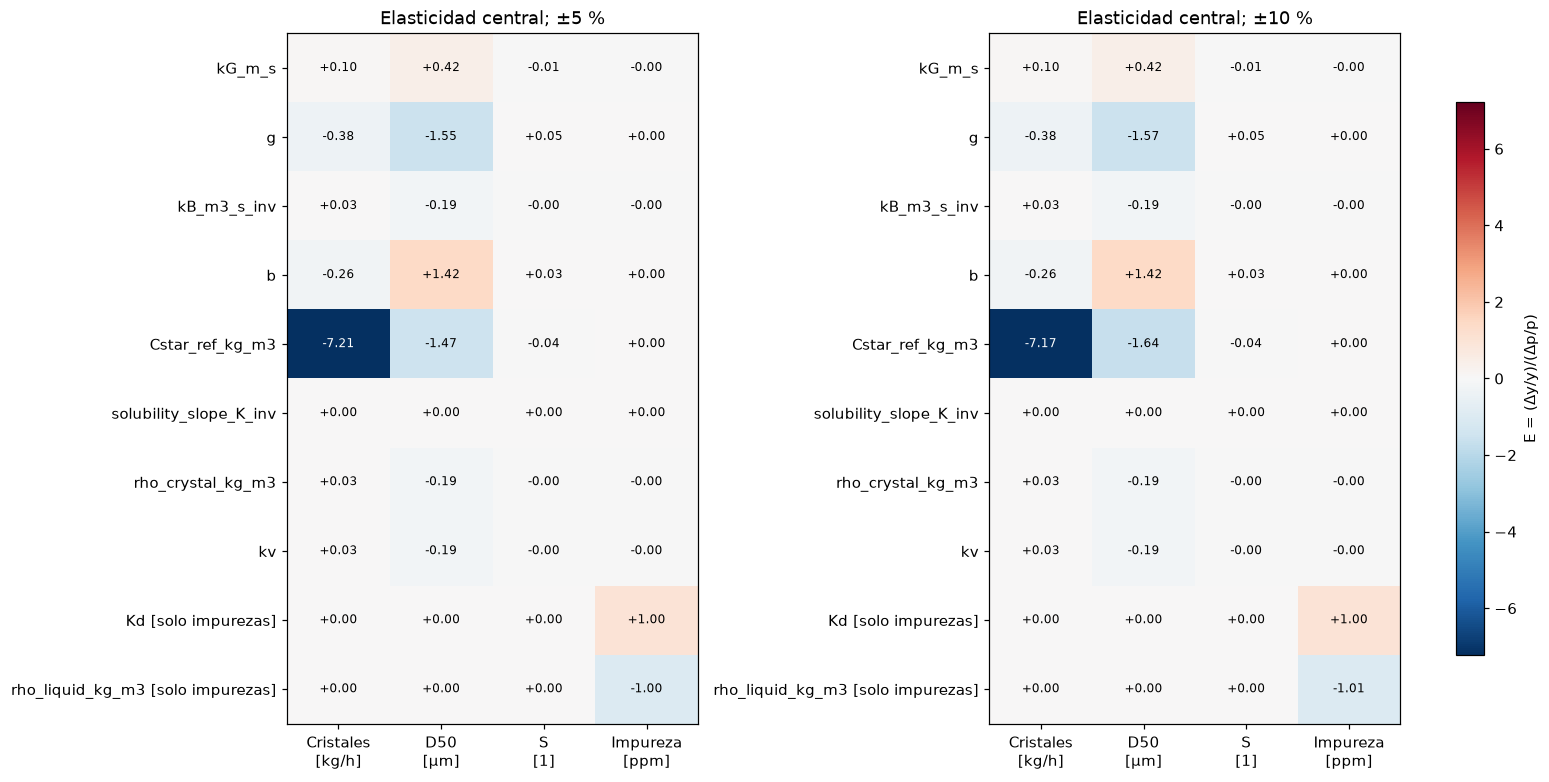

,crystal_flow_kg_h,D50_um,S,impurity_ppm,grupo,max_abs_E,influencia
Cstar_ref_kg_m3,-7.173386,-1.643189,-0.040017,0.001699,DPBE: termodinámico,7.173386,activa
g,-0.375918,-1.569144,0.050244,0.000089,DPBE: cinético,1.569144,activa
b,-0.258451,1.418149,0.034544,0.000061,DPBE: cinético,1.418149,activa
rho_liquid_kg_m3,0.000000,0.000000,0.000000,-1.009857,solo impurezas,1.009857,activa
Kd,0.000000,0.000000,0.000000,0.999763,solo impurezas,0.999763,activa
kG_m_s,0.101900,0.416089,-0.013620,-0.000024,DPBE: cinético,0.416089,activa
kB_m3_s_inv,0.034913,-0.191865,-0.004666,-0.000008,DPBE: cinético,0.191865,activa
kv,0.034913,-0.191865,-0.004666,-0.000008,DPBE: cristalográfico,0.191865,activa
rho_crystal_kg_m3,0.034913,-0.191865,-0.004666,-0.000008,DPBE: cristalográfico,0.191865,activa
solubility_slope_K_inv,0.000000,0.000000,0.000000,0.000000,DPBE: termodinámico,0.000000,despreciable localmente


In [7]:
parameter_records = []
for key, (_, group, low, high) in PARAMETERS.items():
    for r in ANALYSIS['parameter_relative_changes']:
        assert r != 0 and r > -1
        value = BASE[key]*(1+r)
        record = {'parameter': key, 'group': group, 'relative_change': r, 'value': value}
        if not low < value <= high:
            parameter_records.append({**record, 'status': 'fuera de límite'})
            continue
        p = deepcopy(BASE)
        p[key] = value
        result = evaluate(p)
        accepted = result['valid'] and result['has_product']
        for out in output_keys:
            record[f'E_{out}'] = ((result[out]/base[out]-1)/r if accepted else np.nan)
        parameter_records.append({**record, **result,
                                  'status': 'válido' if accepted else 'sin producto o inválido'})
parameter_sensitivity = pd.DataFrame(parameter_records)
central = {}
for h in sorted(set(abs(r) for r in ANALYSIS['parameter_relative_changes'])):
    values = []
    for key in PARAMETERS:
        part = parameter_sensitivity[parameter_sensitivity['parameter'] == key]
        minus = part[np.isclose(part['relative_change'], -h)]
        plus = part[np.isclose(part['relative_change'], h)]
        if len(minus) == 1 and len(plus) == 1 and all(
                df.iloc[0]['status'] == 'válido' for df in (minus, plus)):
            values.append((plus.iloc[0][output_keys].to_numpy(dtype=float)-
                           minus.iloc[0][output_keys].to_numpy(dtype=float))/(2*h*base_y))
        else:
            values.append(np.full(4, np.nan))
    central[h] = np.array(values)
if not central:
    raise ValueError('Configurar al menos un par de perturbaciones ±h.')
h_main = max(central)
elasticities = pd.DataFrame(central[h_main], index=list(PARAMETERS), columns=output_keys)
elasticities['grupo'] = [info[1] for info in PARAMETERS.values()]
elasticities['max_abs_E'] = np.nanmax(abs(central[h_main]), axis=1)
elasticities['influencia'] = np.where(
    elasticities['max_abs_E'] < ANALYSIS['negligible_elasticity'], 'despreciable localmente', 'activa')
labels = [f'{k} [solo impurezas]' if PARAMETERS[k][1] == 'solo impurezas' else k
          for k in PARAMETERS]
fig, axs = plt.subplots(1, len(central), figsize=(7*len(central), 7),
                        constrained_layout=True, squeeze=False)
limit = max(np.nanmax(abs(a)) for a in central.values())
for ax, (h, values) in zip(axs.flat, central.items()):
    im = annotated_heatmap(ax, values, labels, f'Elasticidad central; ±{100*h:g} %', limit)
fig.colorbar(im, ax=axs.ravel().tolist(), label='E = (Δy/y)/(Δp/p)', shrink=.8)
plt.show()
display(elasticities.sort_values('max_abs_E', ascending=False))
print('Perturbaciones excluidas:', int((parameter_sensitivity['status'] != 'válido').sum()))


## 6. Exploración multiobjetivo y frente de Pareto

Se maximiza producción de KNO₃ y se minimiza ppm de ClO₄, variando d, T y τ
dentro de las mismas ventanas operacionales. Una malla cartesiana determinista
incluye BASE y se evalúa con **el mismo DPBE estacionario**. A domina B si su
producción es al menos igual, sus ppm son a lo sumo iguales y mejora estrictamente
algún objetivo. Se conserva cada combinación no dominada, incluso si hubiera
objetivos coincidentes. El frente es **del conjunto muestreado**, no una garantía
de óptimo global continuo. Se excluyen estados inválidos y sin producto.

La alternativa de compromiso minimiza la distancia euclídea al ideal
(producción máxima, impureza mínima) tras normalizar ambos ejes al rango del
frente. Esta selección es una preferencia matemática de igual peso, no un costo
económico. Se identifica cada punto no dominado con un ID y sus condiciones.

Se calcula además la factibilidad **estricta ppm<40**. Es una comparación
exploratoria: **40 ppm corresponde al objetivo del producto refinado**, mientras
que este modelo estima cristal antes del lavado y no predice su efecto.


441 combinaciones; 421 válidas con cristales; 18 no dominadas; 421 con ppm<40.
Puntos descartados por resolución espacial: 13
Puntos sin cristales: 7
Todas las condiciones no dominadas (τ en segundos):
Máxima producción con la restricción exploratoria: P0000 19583.844 kg/h


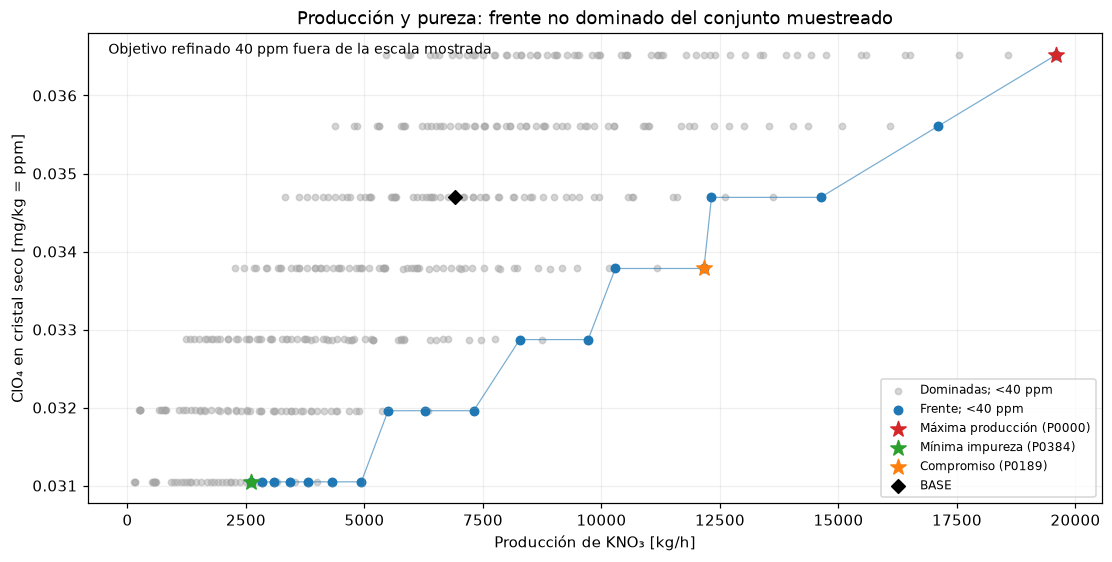

,elección,id,feed_dilution_fraction,crystallizer_temperature_C,residence_time,Q_m3_h,crystal_flow_kg_h,D50_um,S,impurity_ppm,quality_feasible,distance_to_ideal
0,Máxima producción,P0000,0.000,35.0,5076.380729,468.050000,19583.843629,155.599276,1.040517,0.036517,True,1.000000
384,Mínima impureza,P0384,0.150,35.0,11844.888367,200.592857,2606.568641,146.010294,1.016262,0.031048,True,1.000000
189,Compromiso,P0189,0.075,35.0,5076.380729,468.050000,12161.378090,141.625886,1.036769,0.033783,True,0.664303


,id,feed_dilution_fraction,crystallizer_temperature_C,residence_time,Q_m3_h,crystal_flow_kg_h,D50_um,S,impurity_ppm,quality_feasible
384,P0384,0.150,35.0,11844.888367,200.592857,2606.568641,146.010294,1.016262,0.031048,True
383,P0383,0.150,35.0,10716.803760,221.707895,2832.069171,142.655368,1.017549,0.031048,True
382,P0382,0.150,35.0,9588.719154,247.791176,3099.780609,138.996932,1.019093,0.031048,True
381,P0381,0.150,35.0,8460.634548,280.830000,3422.316376,134.890316,1.020980,0.031048,True
380,P0380,0.150,35.0,7332.549941,324.034615,3817.405169,130.266866,1.023349,0.031048,True
379,P0379,0.150,35.0,6204.465335,382.950000,4310.082941,124.910386,1.026421,0.031048,True
378,P0378,0.150,35.0,5076.380729,468.050000,4934.435009,118.549977,1.030581,0.031049,True
317,P0317,0.125,35.0,7332.549941,324.034615,5499.385119,139.990194,1.025155,0.031960,True
316,P0316,0.125,35.0,6204.465335,382.950000,6277.972824,134.538620,1.028530,0.031960,True
315,P0315,0.125,35.0,5076.380729,468.050000,7304.054776,128.068333,1.033135,0.031960,True


In [8]:
decision_keys = [key for key, _ in heatmap_inputs]
axes = []
for key, count in zip(decision_keys, ANALYSIS['pareto_points_per_axis']):
    levels = np.linspace(*ANALYSIS['operating_bounds'][key], count)
    near_base = np.isclose(levels, BASE[key], rtol=1e-12, atol=1e-12)
    if near_base.any():
        levels[np.argmin(abs(levels-BASE[key]))] = BASE[key]
    else:
        levels = np.r_[levels, BASE[key]]
    axes.append(np.sort(levels))
pareto_records = []
for number, values in enumerate(product(*axes)):
    p = deepcopy(BASE)
    p.update(dict(zip(decision_keys, map(float, values))))
    result = evaluate(p)
    pareto_records.append({'id': f'P{number:04d}', **dict(zip(decision_keys, values)), **result})
exploration = pd.DataFrame(pareto_records)
eligible = exploration['valid'] & exploration['has_product'] & np.isfinite(exploration['impurity_ppm'])
exploration['quality_feasible'] = eligible & (exploration['impurity_ppm'] < ANALYSIS['quality_limit_ppm'])
exploration['non_dominated'] = False


def nondominated_mask(production, impurity):
    production, impurity = np.asarray(production), np.asarray(impurity)
    keep = np.ones(len(production), dtype=bool)
    for i in range(len(production)):
        dominates = ((production >= production[i]) & (impurity <= impurity[i]) &
                     ((production > production[i]) | (impurity < impurity[i])))
        keep[i] = not np.any(dominates)
    return keep


eligible_points = exploration.loc[eligible]
keep = nondominated_mask(eligible_points['crystal_flow_kg_h'], eligible_points['impurity_ppm'])
exploration.loc[eligible_points.index, 'non_dominated'] = keep
front = exploration[exploration['non_dominated']].sort_values('crystal_flow_kg_h').copy()
if len(front) == 0:
    raise RuntimeError('No hay soluciones válidas con producto.')
q = front['crystal_flow_kg_h'].to_numpy()
z = front['impurity_ppm'].to_numpy()
qnorm = (q-q.min())/max(np.ptp(q), 1e-30)
znorm = (z-z.min())/max(np.ptp(z), 1e-30)
front['distance_to_ideal'] = np.hypot(1-qnorm, znorm)
representative_indices = [front['crystal_flow_kg_h'].idxmax(), front['impurity_ppm'].idxmin(),
                          front['distance_to_ideal'].idxmin()]
representatives = front.loc[representative_indices].copy()
representatives.insert(0, 'elección', ['Máxima producción', 'Mínima impureza', 'Compromiso'])

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for quality, marker, suffix in [(True, 'o', '<40 ppm'), (False, 'x', '≥40 ppm')]:
    dominated = exploration[eligible & ~exploration['non_dominated'] &
                             (exploration['quality_feasible'] == quality)]
    if len(dominated):
        ax.scatter(dominated['crystal_flow_kg_h'], dominated['impurity_ppm'],
                   s=17, color='0.65', alpha=.45, marker=marker, label=f'Dominadas; {suffix}')
    points = front[front['quality_feasible'] == quality]
    if len(points):
        ax.scatter(points['crystal_flow_kg_h'], points['impurity_ppm'],
                   s=30, color='tab:blue', marker=marker, label=f'Frente; {suffix}')
ax.plot(front['crystal_flow_kg_h'], front['impurity_ppm'], color='tab:blue', lw=.8, alpha=.6)
for (_, row), color in zip(representatives.iterrows(), ['tab:red', 'tab:green', 'tab:orange']):
    ax.scatter(row['crystal_flow_kg_h'], row['impurity_ppm'], color=color,
               s=110, marker='*', zorder=5, label=f"{row['elección']} ({row['id']})")
ax.scatter(base['crystal_flow_kg_h'], base['impurity_ppm'], marker='D', color='black', s=40, label='BASE')
limit_ppm = ANALYSIS['quality_limit_ppm']
if z.min()/2 <= limit_ppm <= exploration.loc[eligible, 'impurity_ppm'].max()*2:
    ax.axhline(limit_ppm, color='tab:red', ls='--', label='Objetivo refinado: 40 ppm')
else:
    ax.text(.02, .98, 'Objetivo refinado 40 ppm fuera de la escala mostrada',
            transform=ax.transAxes, va='top', fontsize=9)
ax.set(xlabel='Producción de KNO₃ [kg/h]', ylabel='ClO₄ en cristal seco [mg/kg = ppm]',
       title='Producción y pureza: frente no dominado del conjunto muestreado')
ax.legend(fontsize=8, loc='best')
plt.show()

front_columns = ['id', *decision_keys, 'Q_m3_h', *output_keys, 'quality_feasible']
display(representatives[['elección', *front_columns, 'distance_to_ideal']])
print(f'{len(exploration)} combinaciones; {eligible.sum()} válidas con cristales; '
      f'{len(front)} no dominadas; {exploration.quality_feasible.sum()} con ppm<40.')
print('Puntos descartados por resolución espacial:', int((~exploration['mesh_resolved']).sum()))
print('Puntos sin cristales:', int((~exploration['has_product']).sum()))
print('Todas las condiciones no dominadas (τ en segundos):')
with pd.option_context('display.max_rows', None):
    display(front[front_columns])
feasible_points = exploration[exploration['quality_feasible']]
if len(feasible_points):
    best_quality_constrained = feasible_points.loc[feasible_points['crystal_flow_kg_h'].idxmax()]
    print('Máxima producción con la restricción exploratoria:',
          best_quality_constrained['id'],
          f"{best_quality_constrained['crystal_flow_kg_h']:.3f} kg/h")


## 7. Verificaciones numéricas

Se verifican: inventario acumulado y balance estacionario de KNO₃, positividad,
balance de traza, consistencia μ₃↔masa y desigualdades de momentos; identidad
del número total; tamaño finito de dominio; φs; estado estacionario y acuerdo
del transitorio con el DPBE algebraico. Se refina la malla (N→2N), el paso
temporal (Δt_max→Δt_max/2), y se compara el caso base con la solución continua
de referencia n=(B/G)exp[−L/(Gτ)], μₖ=k!BGᵏτ^(k+1).

El balance exactamente conservativo no basta para validar la CSD: por eso se
incluyen comparaciones de malla y del límite continuo, incluido D50. Los
umbrales numéricos son opciones configurables, no incertidumbres físicas.


In [9]:
fine_num = {**NUM, 'bins': 2*NUM['bins']}
fine = evaluate(BASE, fine_num)
refined_time = integrate(BASE, {**NUM, 'max_step_s': NUM['max_step_s']/2})
final = trajectory.iloc[-1]
final_half_step = refined_time['trajectory'].iloc[-1]
mesh_changes = {out: abs(fine[out]/base[out]-1) for out in output_keys}
assert np.allclose(refined_time['trajectory']['time_s'], trajectory['time_s'])
# Se compara toda la trayectoria; comparar solo el equilibrio ocultaría error temporal.
time_changes = {out: np.nanmax(abs(refined_time['trajectory'][out].to_numpy()-
                                  trajectory[out].to_numpy()))/max(abs(base[out]), 1e-30)
                for out in output_keys if out != 'impurity_ppm'}
transient_changes = {out: abs(final[out]/base[out]-1)
                     for out in output_keys if out != 'impurity_ppm'}

S, G, B = kinetics(base_dpbe['C'], BASE)
tau = BASE['residence_time']
analytic_moments = np.array([math.factorial(k)*B*G**k*tau**(k+1) for k in range(4)])
discrete_moments = np.array([base[f'mu{k}'] for k in range(4)])
fine_moments = np.array([fine[f'mu{k}'] for k in range(4)])
# Para aislar el error espacial, evaluar ambos tamaños de malla a C, G y B del BASE.
def imposed_rates_moments(bins):
    gr = make_grid(BASE, {**NUM, 'bins': bins})
    a = G/gr['dl']
    N = B/(a+1/tau)*(a/(a+1/tau))**np.arange(bins)
    return gr['q'] @ N, d50(N, gr)

imposed, imposed_d50 = imposed_rates_moments(NUM['bins'])
imposed_fine, imposed_fine_d50 = imposed_rates_moments(2*NUM['bins'])
moment_errors = abs(imposed/analytic_moments-1)
moment_errors_fine = abs(imposed_fine/analytic_moments-1)
x50 = bisect_root(lambda x: 1-np.exp(-x)*(1+x+x*x/2+x**3/6)-.5, 0, 30)
analytic_d50 = 1e6*x50*G*tau
benchmark = pd.DataFrame({
    'magnitud': ['mu0', 'mu1', 'mu2', 'mu3', 'D50_um'],
    'continuo': [*analytic_moments, analytic_d50],
    'DPBE_N': [*imposed, imposed_d50],
    'DPBE_2N': [*imposed_fine, imposed_fine_d50],
    'error_rel_N': [*moment_errors, abs(imposed_d50/analytic_d50-1)],
    'error_rel_2N': [*moment_errors_fine, abs(imposed_fine_d50/analytic_d50-1)],
})
display(benchmark)
display(pd.DataFrame({'cambio malla': mesh_changes,
                      'cambio paso (máximo transitorio)': time_changes,
                      'transitorio vs estacionario': transient_changes}))

# Identidades de momentos comprobadas en cada muestra temporal, incluido el arranque vacío.
m0, m1, m2, m3 = [trajectory[f'mu{k}'].to_numpy() for k in range(4)]
moment_inequalities = (np.all(m1*m1 <= m0*m2*(1+1e-12)+1e-30) and
                        np.all(m2*m2 <= m1*m3*(1+1e-12)+1e-30))
dN, R, tail, number_tail = population_terms(base_dpbe['C'], base_dpbe['N'], BASE, grid)
number_identity = abs(dN.sum()-(B-base['mu0']/tau-number_tail))/max(B, 1)
mass_identity = abs(base['M_kg_m3']-BASE['rho_crystal_kg_m3']*BASE['kv']*base['mu3'])/base['M_kg_m3']
post_only_invariant = True
for key in ('Kd', 'rho_liquid_kg_m3'):
    changed = deepcopy(BASE)
    changed[key] *= 1.05
    alt = stationary_dpbe(changed)
    post_only_invariant &= np.array_equal(alt['N'], base_dpbe['N']) and alt['C'] == base_dpbe['C']

# Pruebas límite: sin nucleación en subsaturación, CSD vacía y no producto.
undersaturated = deepcopy(BASE)
undersaturated['feed_dilution_fraction'] = .5
empty = evaluate(undersaturated)
diluted = feed(BASE)
dilution_identity = all(np.isclose(diluted[k]/v, 1-BASE['feed_dilution_fraction'])
                        for k, v in BASE['feed_stock_kg_m3'].items())
toy = nondominated_mask([1, 2, 2, 3], [2, 2, 1, 3])
# El coeficiente térmico es activo lejos de Tref aunque su elasticidad local sea cero.
off_anchor = deepcopy(BASE)
off_anchor['crystallizer_temperature_C'] += 3
off_anchor_changed = deepcopy(off_anchor)
off_anchor_changed['solubility_slope_K_inv'] *= 1.1
thermal_active_off_anchor = not np.isclose(evaluate(off_anchor)['crystal_flow_kg_h'],
                                         evaluate(off_anchor_changed)['crystal_flow_kg_h'])

checks = {
    'masa_transitoria': transient['max_mass_relative'] < NUM['mass_tolerance'],
    'masa_estacionaria': base['mass_residual'] < NUM['mass_tolerance'],
    'no_negatividad': transient['min_C'] >= 0 and transient['min_N'] >= 0,
    'momento_masa': mass_identity < 1e-12,
    'desigualdades_momentos': moment_inequalities,
    'balance_numero': number_identity < 1e-12,
    'estado_estacionario': base['stationary_residual'] < NUM['stationary_tolerance'],
    'derivada_transitoria_final': transient['final_rate_residual'] < NUM['transient_stationary_tolerance'],
    'transitorio_vs_estacionario': max(transient_changes.values()) < NUM['transient_stationary_tolerance'],
    'refinamiento_malla': max(mesh_changes.values()) < NUM['mesh_tolerance'],
    'refinamiento_paso': max(time_changes.values()) < NUM['time_tolerance'],
    'convergencia_momentos_continuos': bool(np.all(moment_errors_fine[1:] < moment_errors[1:])),
    'convergencia_D50_continuo': abs(imposed_fine_d50/analytic_d50-1) < abs(imposed_d50/analytic_d50-1),
    'truncamiento_base': base['tail_mass_fraction'] < NUM['tail_tolerance'],
    'volumen_solido': base['phi_s'] < NUM['solid_volume_fraction_limit'],
    'balance_impureza': base['impurity_balance_relative'] < 1e-10,
    'impurezas_desacopladas': bool(post_only_invariant),
    'dilucion_todos_solutos': dilution_identity,
    'residencia_caudal': np.isclose(flow(BASE)*BASE['residence_time'], BASE['volume_m3']),
    'subsaturacion_sin_producto': empty['valid'] and not empty['has_product'] and np.isnan(empty['D50_um']),
    'dominancia_ejemplo_conocido': np.array_equal(toy, [False, False, True, True]),
    'pendiente_termica_activa_fuera_referencia': thermal_active_off_anchor,
    'residuos_estacionarios_exploracion': bool(
        (exploration['stationary_residual'] < NUM['stationary_tolerance']).all()),
    'malla_resuelta_en_puntos_aceptados': bool(exploration.loc[eligible, 'mesh_resolved'].all()),
    'traza_conservativa_en_exploracion': bool((exploration['impurity_balance_relative'] < 1e-10).all()),
}
checks = {k: bool(v) for k, v in checks.items()}
display(pd.DataFrame({'verificación': list(checks), 'cumple': list(checks.values())}))
print('Máximo error relativo de masa temporal:', transient['max_mass_relative'])
print('Máxima fuga relativa por Lmax en exploración:', exploration['tail_mass_fraction'].max())
print('Máxima φs en exploración:', exploration['phi_s'].max())
assert all(checks.values()), {key: value for key, value in checks.items() if not value}


Máximo error relativo de masa temporal: 6.031666167277991e-15
Máxima fuga relativa por Lmax en exploración: 1.2484552986105634e-07
Máxima φs en exploración: 0.021519562883211846


,magnitud,continuo,DPBE_N,DPBE_2N,error_rel_N,error_rel_2N
0,mu0,4.962251e+10,4.962251e+10,4.962251e+10,4.550804e-13,2.933209e-13
1,mu1,2.033525e+06,2.095553e+06,2.064539e+06,3.050276e-02,1.525138e-02
2,mu2,1.666673e+02,1.769383e+02,1.717770e+02,6.162580e-02,3.065783e-02
3,mu3,2.049003e-02,2.240971e-02,2.143867e-02,9.368872e-02,4.629807e-02
4,D50_um,1.504807e+02,1.550135e+02,1.527642e+02,3.012236e-02,1.517494e-02


,cambio malla,cambio paso (máximo transitorio),transitorio vs estacionario
crystal_flow_kg_h,1.533286e-03,0.000016,2.219346e-10
D50_um,6.093373e-03,0.000052,3.960943e-10
S,2.049333e-04,0.000002,1.101785e-12
impurity_ppm,3.631963e-07,NaN,NaN


,verificación,cumple
0,masa_transitoria,True
1,masa_estacionaria,True
2,no_negatividad,True
3,momento_masa,True
4,desigualdades_momentos,True
5,balance_numero,True
6,estado_estacionario,True
7,derivada_transitoria_final,True
8,transitorio_vs_estacionario,True
9,refinamiento_malla,True


## 8. Conclusiones técnicas y archivos reproducibles

Las conclusiones siguientes se calculan a partir de los resultados, para que
se actualicen cuando cambie la configuración. Un parámetro despreciable se
identifica solo en este caso base, escala de perturbación y ventana de modelo.
Las diferencias entre valores ensayados no representan incertidumbre estadística.


In [10]:
ranking = elasticities.sort_values('max_abs_E', ascending=False)
negligible = ranking.index[ranking['influencia'] == 'despreciable localmente'].tolist()
most_influential = ', '.join(ranking.index[:3])
max_row, min_row, compromise_row = [row for _, row in representatives.iterrows()]
quality_text = ('La restricción de 40 ppm no es activa en la exploración.'
                if exploration.loc[eligible, 'quality_feasible'].all()
                else 'La restricción de 40 ppm excluye parte de la exploración.')
display(Markdown(f"""
- **BASE estacionario:** {base['crystal_flow_kg_h']:.2f} kg/h de KNO₃,
  D50={base['D50_um']:.2f} µm, S={base['S']:.5f},
  ClO₄={base['impurity_ppm']:.6f} ppm.
- **Sensibilidad constitutiva:** mayor elasticidad máxima entre las cuatro salidas:
  {most_influential}. Despreciables localmente: {', '.join(negligible) or 'ninguno'}.
  La pendiente térmica es cero a T=Tref por construcción; se verifica su efecto a Tref+3 °C.
  Kd y ρl afectan exclusivamente las ppm; no cambian el DPBE.
- **Compromiso producción–pureza muestreado:** máxima producción
  {max_row['crystal_flow_kg_h']:.2f} kg/h a {max_row['impurity_ppm']:.6f} ppm;
  mínima impureza {min_row['impurity_ppm']:.6f} ppm a
  {min_row['crystal_flow_kg_h']:.2f} kg/h. Alternativa de igual peso
  **{compromise_row['id']}**: d={compromise_row['feed_dilution_fraction']:.3f},
  T={compromise_row['crystallizer_temperature_C']:.2f} °C,
  τ={compromise_row['residence_time']/3600:.3f} h,
  {compromise_row['crystal_flow_kg_h']:.2f} kg/h y {compromise_row['impurity_ppm']:.6f} ppm.
- **Verificación:** {sum(checks.values())}/{len(checks)} controles aprobados.
  Cambio máximo entre malla y malla doble: {100*max(mesh_changes.values()):.2f} %;
  entre pasos temporales: {100*max(time_changes.values()):.4f} %.
- **Alcance de la pureza:** {quality_text} El resultado depende del supuesto de
  ensayo en mg/L y Kd=0.01; no demuestra cumplimiento real del producto refinado.
  La menor impureza con dilución procede de diluir la traza; no hay un mecanismo
  adicional de purificación dependiente del tamaño o de la temperatura.
"""))

# No hay escrituras fuera de la carpeta de esta entrega. Cada ejecución crea una salida nueva.
notebook_folder = 'msmpr_kno3_dpbe_pareto'
cwd = Path.cwd().resolve()
if cwd.name == notebook_folder:
    delivery_root = cwd
elif (cwd/notebook_folder).is_dir():
    delivery_root = cwd/notebook_folder
else:
    # Permite usar una copia independiente del notebook desde su propia carpeta.
    delivery_root = cwd
run_root = delivery_root/'resultados'/datetime.now(timezone.utc).strftime('ejecucion_%Y%m%dT%H%M%S_%fZ')
run_root.mkdir(parents=True, exist_ok=False)
for name, table in {
    'trayectoria_base': trajectory, 'sensibilidad_operacional': operating_sensitivity,
    'sensibilidad_parametros': parameter_sensitivity, 'elasticidades': elasticities,
    'exploracion_pareto': exploration, 'frente_pareto': front,
    'soluciones_representativas': representatives, 'benchmark_momentos': benchmark,
    'parametros': parameter_table,
}.items():
    table.to_csv(run_root/f'{name}.csv', index=(name == 'elasticidades'))
pd.DataFrame({'L_left_m': grid['edges'][:-1], 'L_right_m': grid['edges'][1:],
              'n_final_m4_inv': transient['N']/grid['dl'],
              'n_estacionario_m4_inv': base_dpbe['N']/grid['dl']}).to_csv(run_root/'CSD_base.csv', index=False)
source_paths = ['msmpr_dpbe/Evaporative_MSMPR_DPBE.ipynb',
                'examples/msmpr/template_model.py', 'PBE_sol/PBE.py',
                'PBE_sol/cryst.py', 'msmpr_dpbe/population_balance.py',
                'docs/kno3_model_basis.md', 'msmpr_dpbe/auditoria_parametros.md',
                'investigacion_parametros_DPBE/informe_parametros.md']
hashes = {relative: hashlib.sha256((delivery_root.parent/relative).read_bytes()).hexdigest()
          for relative in source_paths if (delivery_root.parent/relative).is_file()}
report = {
    'BASE': BASE, 'INITIAL': INITIAL, 'NUM': NUM, 'ANALYSIS': ANALYSIS,
    'base_stationary': base, 'checks': checks, 'mesh_changes': mesh_changes,
    'time_changes': time_changes, 'transient_stationary_changes': transient_changes,
    'max_mass_relative': transient['max_mass_relative'],
    'steady_final_rate_residual': transient['final_rate_residual'],
    'source_sha256': hashes,
    'environment': {'python': platform.python_version(), 'numpy': np.__version__,
                    'matplotlib': matplotlib.__version__, 'pandas': pd.__version__},
    'pareto': {'evaluated': len(exploration), 'valid_with_product': int(eligible.sum()),
               'non_dominated': len(front), 'quality_feasible': int(exploration.quality_feasible.sum()),
               'unresolved_mesh': int((~exploration['mesh_resolved']).sum()),
               'no_product': int((~exploration['has_product']).sum()),
               'representatives': representatives[['elección', 'id']].to_dict('records')},
}
with (run_root/'verificacion_y_configuracion.json').open('x', encoding='utf-8') as f:
    json.dump(report, f, indent=2, ensure_ascii=False, default=lambda x: x.item())
print('Resultados exportados:', run_root)
print('Ejecución completa; todas las verificaciones aprobadas.')


Resultados exportados: C:\Users\SrLeo\OneDrive\Desktop\do-crystal-main\msmpr_kno3_dpbe_pareto\resultados\ejecucion_20261018T195645_700842Z
Ejecución completa; todas las verificaciones aprobadas.



- **BASE estacionario:** 6919.87 kg/h de KNO₃,
  D50=155.01 µm, S=1.02422,
  ClO₄=0.034697 ppm.
- **Sensibilidad constitutiva:** mayor elasticidad máxima entre las cuatro salidas:
  Cstar_ref_kg_m3, g, b. Despreciables localmente: solubility_slope_K_inv.
  La pendiente térmica es cero a T=Tref por construcción; se verifica su efecto a Tref+3 °C.
  Kd y ρl afectan exclusivamente las ppm; no cambian el DPBE.
- **Compromiso producción–pureza muestreado:** máxima producción
  19583.84 kg/h a 0.036517 ppm;
  mínima impureza 0.031048 ppm a
  2606.57 kg/h. Alternativa de igual peso
  **P0189**: d=0.075,
  T=35.00 °C,
  τ=1.410 h,
  12161.38 kg/h y 0.033783 ppm.
- **Verificación:** 25/25 controles aprobados.
  Cambio máximo entre malla y malla doble: 0.61 %;
  entre pasos temporales: 0.0052 %.
- **Alcance de la pureza:** La restricción de 40 ppm no es activa en la exploración. El resultado depende del supuesto de
  ensayo en mg/L y Kd=0.01; no demuestra cumplimiento real del producto refinado.
  La menor impureza con dilución procede de diluir la traza; no hay un mecanismo
  adicional de purificación dependiente del tamaño o de la temperatura.
